<a href="https://colab.research.google.com/github/alameenShameer/Horror_Movie_EDA_Preprocessing/blob/vyas_scaling_encoding/Horror_Movie_EDA_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Horror Movies Dataset — Complete Data Preprocessing & EDA Workflow

**Team:** Al Ameen · Nikhil · Devika · Vyas · Felicia  
**Dataset:** `horror_movies.csv`  
**Purpose:** Exploratory data analysis and preparation of a supervised regression dataset.

## Team task allocation

| Member | Responsibility |
|---|---|
| **Al Ameen** | Dataset loading, inspection and EDA |
| **Nikhil** | Data cleaning and feature engineering |
| **Devika** | Distribution and categorical analysis; target/leakage review |
| **Vyas** | Split and numerical/categorical preprocessing |
| **Felicia** | Target review, imbalance applicability, correlation, feature selection and verification |

## Prediction objective

**Target column: `vote_average`**

The task is to predict a movie's average audience rating (`vote_average`). This is a **regression problem** because the target is numeric and continuous-like, not a class label.



## 1. Import Libraries
**Owner: Al Ameen**


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")

## 2. Dataset Loading
**Owner: Al Ameen**

Upload `horror_movies.csv` to the Colab session, or place it in the same folder as this notebook.

In [2]:

DATA_PATH = '/content/horror_movies.csv'
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Shape: (32540, 20)


,id,original_title,title,original_language,overview,tagline,release_date,poster_path,popularity,vote_count,vote_average,budget,revenue,runtime,status,adult,backdrop_path,genre_names,collection,collection_name
0,760161,Orphan: First Kill,Orphan: First Kill,en,"After escaping from an Estonian psychiatric facility, Leena Klammer travels to America by impers...",There's always been something wrong with Esther.,2022-07-27,/pHkKbIRoCe7zIFvqan9LFSaQAde.jpg,5088.584,902,6.9,0,9572765,99,Released,False,/5GA3vV1aWWHTSDO5eno8V5zDo8r.jpg,"Horror, Thriller",760193.0,Orphan Collection
1,760741,Beast,Beast,en,A recently widowed man and his two teenage daughters travel to a game reserve in South Africa. H...,Fight for family.,2022-08-11,/xIGr7UHsKf0URWmyyd5qFMAq4d8.jpg,2172.338,584,7.1,0,56000000,93,Released,False,/2k9tBql5GYH328Krj66tDT9LtFZ.jpg,"Adventure, Drama, Horror",NaN,NaN
2,882598,Smile,Smile,en,"After witnessing a bizarre, traumatic incident involving a patient, Dr. Rose Cotter starts exper...","Once you see it, it’s too late.",2022-09-23,/hiaeZKzwsk4y4atFhmncO5KRxeT.jpg,1863.628,114,6.8,17000000,45000000,115,Released,False,/mVNPfpydornVe4H4UCIk7WevWjf.jpg,"Horror, Mystery, Thriller",NaN,NaN
3,756999,The Black Phone,The Black Phone,en,"Finney Blake, a shy but clever 13-year-old boy, is abducted by a sadistic killer and trapped in ...",Never talk to strangers.,2022-06-22,/lr11mCT85T1JanlgjMuhs9nMht4.jpg,1071.398,2736,7.9,18800000,161000000,103,Released,False,/AfvIjhDu9p64jKcmohS4hsPG95Q.jpg,"Horror, Thriller",NaN,NaN
4,772450,Presencias,Presences,es,"A man who loses his wife and goes to seclude himself in a cabin in the woods, where strange thin...",NaN,2022-09-07,/dgDT3uol3mdvwEg0jt1ble3l9hw.jpg,1020.995,83,7.0,0,0,0,Released,False,/ojfzhdwRemcDt1I6pao6vVLw9AA.jpg,Horror,NaN,NaN


## 3. Initial Data Inspection
**Owner: Al Ameen**

Inspect shape, columns, data types, descriptive statistics, missing values, duplicates and distinct values. This establishes the baseline before modifying the data.

In [3]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nNumerical summary:")
display(df.describe().T)

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nDistinct values per column:")
display(df.nunique(dropna=False).sort_values().to_frame("unique_count"))

Rows and columns: (32540, 20)

Column names:
['id', 'original_title', 'title', 'original_language', 'overview', 'tagline', 'release_date', 'poster_path', 'popularity', 'vote_count', 'vote_average', 'budget', 'revenue', 'runtime', 'status', 'adult', 'backdrop_path', 'genre_names', 'collection', 'collection_name']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32540 entries, 0 to 32539
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 32540 non-null  int64  
 1   original_title     32540 non-null  object 
 2   title              32540 non-null  object 
 3   original_language  32540 non-null  object 
 4   overview           31254 non-null  object 
 5   tagline            12706 non-null  object 
 6   release_date       32540 non-null  object 
 7   poster_path        28066 non-null  object 
 8   popularity         32540 non-null  float64
 9   vote_count 

,count,mean,std,min,25%,50%,75%,max
id,32540.0,4.459108e+05,3.057447e+05,17.0,146494.75,426521.00,707534.00000,1.033095e+06
popularity,32540.0,4.013456e+00,3.751347e+01,0.0,0.60,0.84,2.24325,5.088584e+03
vote_count,32540.0,6.269149e+01,4.208875e+02,0.0,0.00,2.00,11.00000,1.690000e+04
vote_average,32540.0,3.335728e+00,2.876002e+00,0.0,0.00,4.00,5.70000,1.000000e+01
budget,32540.0,5.431266e+05,4.542668e+06,0.0,0.00,0.00,0.00000,2.000000e+08
revenue,32540.0,1.349747e+06,1.443048e+07,0.0,0.00,0.00,0.00000,7.018426e+08
runtime,32540.0,6.214290e+01,4.099853e+01,0.0,14.00,80.00,91.00000,6.830000e+02
collection,2306.0,4.815349e+05,3.244982e+05,656.0,155421.00,471259.00,759067.25000,1.033032e+06



Missing values:


,missing_count
collection,30234
collection_name,30234
tagline,19834
backdrop_path,18995
poster_path,4474
overview,1286
original_title,0
id,0
original_language,0
title,0



Exact duplicate rows: 0

Distinct values per column:


,unique_count
adult,1
status,4
vote_average,92
original_language,97
runtime,212
genre_names,772
budget,783
collection,816
collection_name,816
vote_count,1105


### Initial observations

- The dataset contains movie metadata, financial fields, popularity/voting measures, release dates, genre strings and image-path fields.
- `overview`, `tagline`, `poster_path`, `backdrop_path`, `collection` and `collection_name` contain missing values.
- `budget`, `revenue` and some `runtime` values may use zero as an unknown/not-recorded placeholder; zero should be reviewed rather than assumed to be a genuine measurement.
- `vote_average` is the selected numeric prediction target for the regression task; inspect its distribution and missing values.

## 4. Exploratory Data Analysis (EDA) — Data Visualization
**Owner: Al Ameen**

Explore numerical distributions, movie release years, language, status, genre frequency, rating and financial fields. These plots describe the raw data; they do not imply causation.

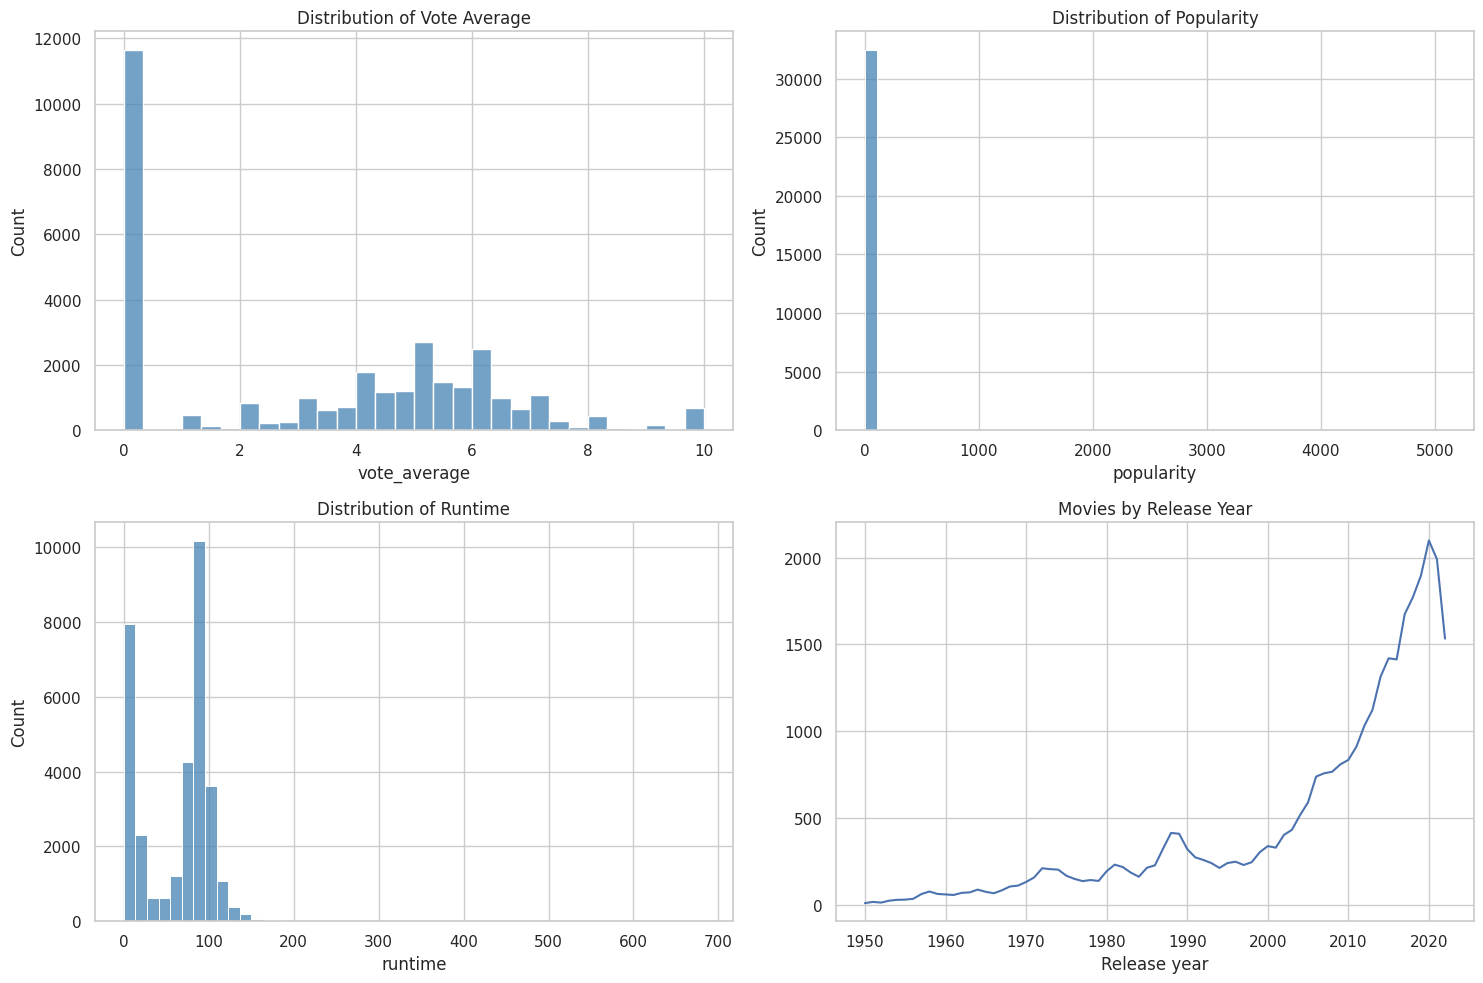

In [4]:
# Parse dates for visualization without changing the original column yet.
eda_dates = pd.to_datetime(df["release_date"], errors="coerce")
release_year = eda_dates.dt.year

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(df["vote_average"], bins=30, kde=False, color="steelblue", ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Vote Average")
sns.histplot(df["popularity"], bins=50, kde=False, color="steelblue", ax=axes[0, 1])
axes[0, 1].set_title("Distribution of Popularity")
sns.histplot(df["runtime"], bins=50, kde=False, color="steelblue", ax=axes[1, 0])
axes[1, 0].set_title("Distribution of Runtime")
release_year.dropna().astype(int).value_counts().sort_index().plot(ax=axes[1, 1])
axes[1, 1].set_title("Movies by Release Year")
axes[1, 1].set_xlabel("Release year")
plt.tight_layout()
plt.show()

1. Numerical data analysis

Plot 1: Distribution of Vote Average
Observations:
- A large number of movies have a vote_average of 0.
- Most movies with non-zero ratings are concentrated between approximately 4 and 7.
- The distribution is not uniform, indicating differences in movie ratings.
- The large number of zero ratings should be investigated because they may represent movies without sufficient audience votes.
Important: Since vote_average is your target column, investigate whether zero represents a genuine rating or an absence of ratings before model training.

Plot 2: Distribution of Popularity
Observations:
- The distribution is highly right-skewed.
- Most movies have relatively low popularity values.
- A small number of movies have extremely high popularity values.
- These extreme values create a long right tail, indicating the presence of potential outliers.


Plot 3: Distribution of Runtime
Observations:
- Most movies have runtimes concentrated approximately between 70 and 110 minutes.
- A considerable number of records have a runtime of zero.
- Some movies have unusually high runtime values.
- The distribution is not normal and contains potential outliers.
Important: Runtime values of zero should be investigated because they may represent missing or unrecorded information.


Plot 4: Movies by Release Year
Observations:
- The number of movies generally increases over the years.
- There is a noticeable increase in movie records after the 2000s.
- The highest number of records appears around 2020.
- A decline is visible in the most recent years, which may be due to incomplete dataset coverage.

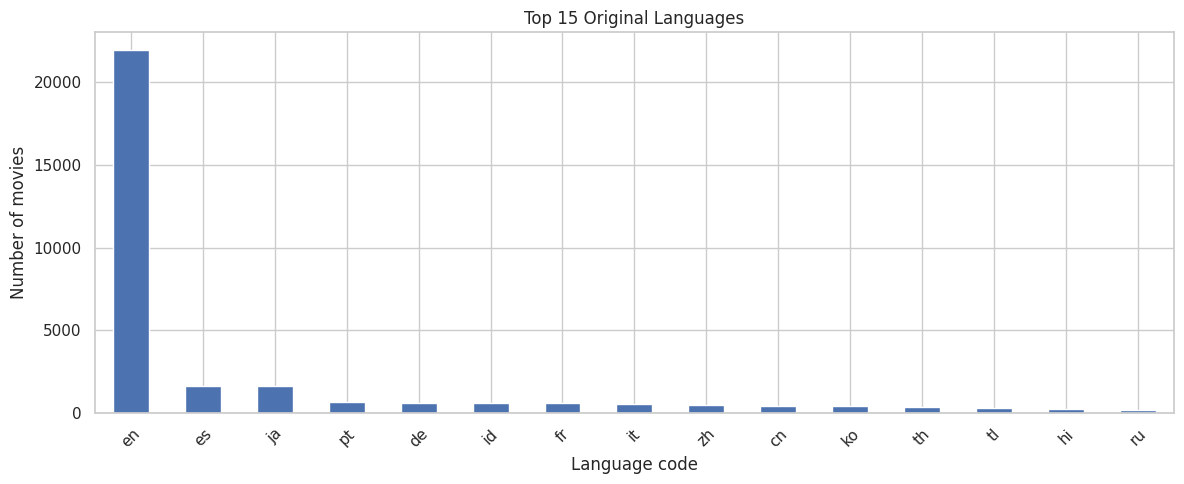

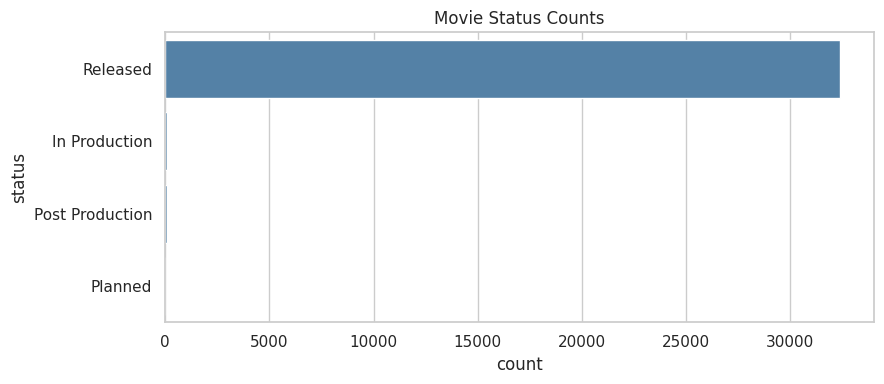

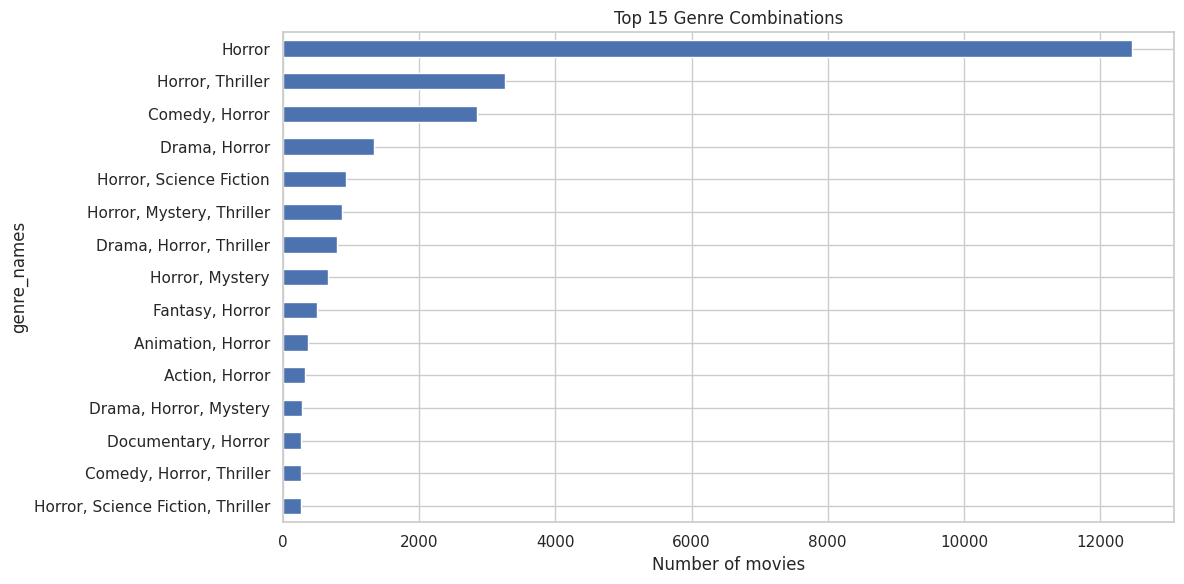

In [5]:
# Top 15 original languages
plt.figure(figsize=(12, 5))
df["original_language"].value_counts().head(15).plot(kind="bar")
plt.title("Top 15 Original Languages")
plt.xlabel("Language code")
plt.ylabel("Number of movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Movie status distribution
plt.figure(figsize=(9, 4))
sns.countplot(data=df, y="status", order=df["status"].value_counts().index, color="steelblue")
plt.title("Movie Status Counts")
plt.tight_layout()
plt.show()

# Most common genre combinations
plt.figure(figsize=(12, 6))
df["genre_names"].value_counts().head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Genre Combinations")
plt.xlabel("Number of movies")
plt.tight_layout()
plt.show()

2. Categorical data analysis

Plot 5: Top 15 Original Languages
Observations:
- English (en) is the dominant original language in the dataset.
- Spanish (es) and Japanese (ja) are the next most frequently represented languages.
- Other languages have considerably fewer movie records.
- The dataset has an imbalanced distribution of movies across original languages.

Plot 6: Movie Status Distribution
Observations:
- The majority of movies have a status of Released.
- Very few movies belong to In Production, Post Production and Planned categories.
- The status distribution is highly imbalanced.
- Most records represent movies that have already been released.

Plot 7: Top 15 Genre Combinations
Observations:
- Horror is the most frequently occurring genre combination.
- Horror and Thriller is the second most common combination.
- Comedy and Horror is another frequently occurring combination.
- Horror appears in almost all the most frequent genre combinations.
- Genre combinations vary in frequency, indicating differences in genre representation.

### Overall EDA Conclusion

- The dataset contains 32,540 movie records and 20 columns.
- The target variable `vote_average` contains a considerable number of zero values that require further investigation.
- Popularity and runtime distributions show skewness and potential outliers.
- English is the most dominant original language.
- Most movies belong to the Released status.
- Horror is the most frequently occurring genre, followed by Horror-Thriller combinations.
- Movie records have generally increased over the years, with a noticeable peak around 2020.
- Missing values, zero placeholders, outliers and categorical distributions need to be considered during data preprocessing.

Overall, the EDA provides an understanding of the dataset's structure, distributions and potential data quality issues before proceeding with data cleaning and feature engineering.

## 5. Data Cleaning
**Owner: Nikhil**

### 5.1 Missing Value Identification
Convert whitespace-only strings to missing values and report missingness before deciding how to handle each field.

In [6]:
df_clean = df.copy()

# Standardize text whitespace and convert empty strings to missing values.
text_cols = df_clean.select_dtypes(include="object").columns
for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()
    df_clean[col] = df_clean[col].replace("", pd.NA)

missing_report = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_percent": (df_clean.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_report)

,missing_count,missing_percent
collection,30234,92.91
collection_name,30234,92.91
tagline,19836,60.96
backdrop_path,18995,58.37
poster_path,4474,13.75
overview,1286,3.95
original_title,0,0.00
id,0,0.00
original_language,0,0.00
title,0,0.00


### 5.2 Duplicate Value Removal
Remove exact duplicate rows. Keep the first occurrence. Do not deduplicate using only a movie title because different films can share titles or have different releases.

In [7]:
rows_before_deduplication = len(df_clean)
duplicates_before = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
duplicates_after = df_clean.duplicated().sum()

print("Duplicate rows before:", duplicates_before)
print("Rows removed:", rows_before_deduplication - len(df_clean))
print("Duplicate rows after:", duplicates_after)
print("Shape after exact duplicate removal:", df_clean.shape)

Duplicate rows before: 0
Rows removed: 0
Duplicate rows after: 0
Shape after exact duplicate removal: (32540, 20)


### 5.3 Handle Inconsistent Data

Normalize text casing/spacing for selected categorical fields. Do not alter descriptive text or movie titles beyond trimming whitespace. Financial zeros are converted to missing because the dataset has a very high proportion of zero budgets/revenues, suggesting that zero often means not reported.

In [8]:
for col in ["original_language", "status"]:
    df_clean[col] = df_clean[col].astype("string").str.strip().str.lower()

# Treat zero budget/revenue/runtime as unavailable values for preprocessing.
# Keep a copy of the raw dataset if zero itself is meaningful for a later analysis.
for col in ["budget", "revenue", "runtime"]:
    df_clean.loc[df_clean[col] == 0, col] = pd.NA

print("Zero placeholders converted to missing values:")
display(df_clean[["budget", "revenue", "runtime"]].isna().sum().to_frame("missing_after_zero_review"))

Zero placeholders converted to missing values:


,missing_after_zero_review
budget,27339
revenue,30964
runtime,2668


### 5.4 Data Type Correction

Parse `release_date` as a datetime field. Convert `adult` to a categorical/bool-like field and ensure numeric metadata remains numeric.

In [9]:
df_clean["release_date"] = pd.to_datetime(df_clean["release_date"], errors="coerce")

numeric_cols_expected = [
    "popularity", "vote_count", "vote_average",
    "budget", "revenue", "runtime", "collection"
]
for col in numeric_cols_expected:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

df_clean["adult"] = df_clean["adult"].astype("boolean")

print(df_clean.dtypes)

id                            int64
original_title               object
title                        object
original_language    string[python]
overview                     object
tagline                      object
release_date         datetime64[ns]
poster_path                  object
popularity                  float64
vote_count                    int64
vote_average                float64
budget                      float64
revenue                     float64
runtime                     float64
status               string[python]
adult                       boolean
backdrop_path                object
genre_names                  object
collection                  float64
collection_name              object
dtype: object


## 6. Feature Engineering
**Owner: Nikhil**

Create interpretable features from existing columns:
- `release_year` and `release_month` from `release_date`.
- `genre_count` from the comma-separated genre list.
- `primary_genre` from the first listed genre.

The engineered features are derived from existing metadata. The original text and date fields will be excluded from the model feature matrix where appropriate.

In [10]:
df_clean["release_year"] = df_clean["release_date"].dt.year
df_clean["release_month"] = df_clean["release_date"].dt.month

genre_text = df_clean["genre_names"].fillna("")
df_clean["genre_count"] = genre_text.apply(
    lambda value: len([g.strip() for g in value.split(",") if g.strip()])
)
df_clean["primary_genre"] = genre_text.apply(
    lambda value: value.split(",")[0].strip().lower() if value.strip() else pd.NA
)

display(df_clean[[
    "release_date", "release_year", "release_month",
    "genre_names", "genre_count", "primary_genre"
]].head(10))

,release_date,release_year,release_month,genre_names,genre_count,primary_genre
0,2022-07-27,2022,7,"Horror, Thriller",2,horror
1,2022-08-11,2022,8,"Adventure, Drama, Horror",3,adventure
2,2022-09-23,2022,9,"Horror, Mystery, Thriller",3,horror
3,2022-06-22,2022,6,"Horror, Thriller",2,horror
4,2022-09-07,2022,9,Horror,1,horror
5,2022-08-18,2022,8,"Horror, Thriller",2,horror
6,2022-09-15,2022,9,"Horror, Mystery, Thriller",3,horror
7,2022-07-20,2022,7,"Horror, Mystery, Science Fiction, Thriller",4,horror
8,2022-04-01,2022,4,"Action, Adventure, Crime, Drama, Horror, Mystery, Thriller, War",8,action
9,2022-03-17,2022,3,"Horror, Mystery, Thriller",3,horror


## 7. Numerical Distribution Analysis — Histogram and KDE for Skewness
**Owner: Devika**

Use histograms and KDE plots to assess distribution shape. KDE is a smoothed estimate and may be unreliable for highly discrete or zero-inflated fields. Skewness is described visually here; no automatic transformation is applied at this stage.

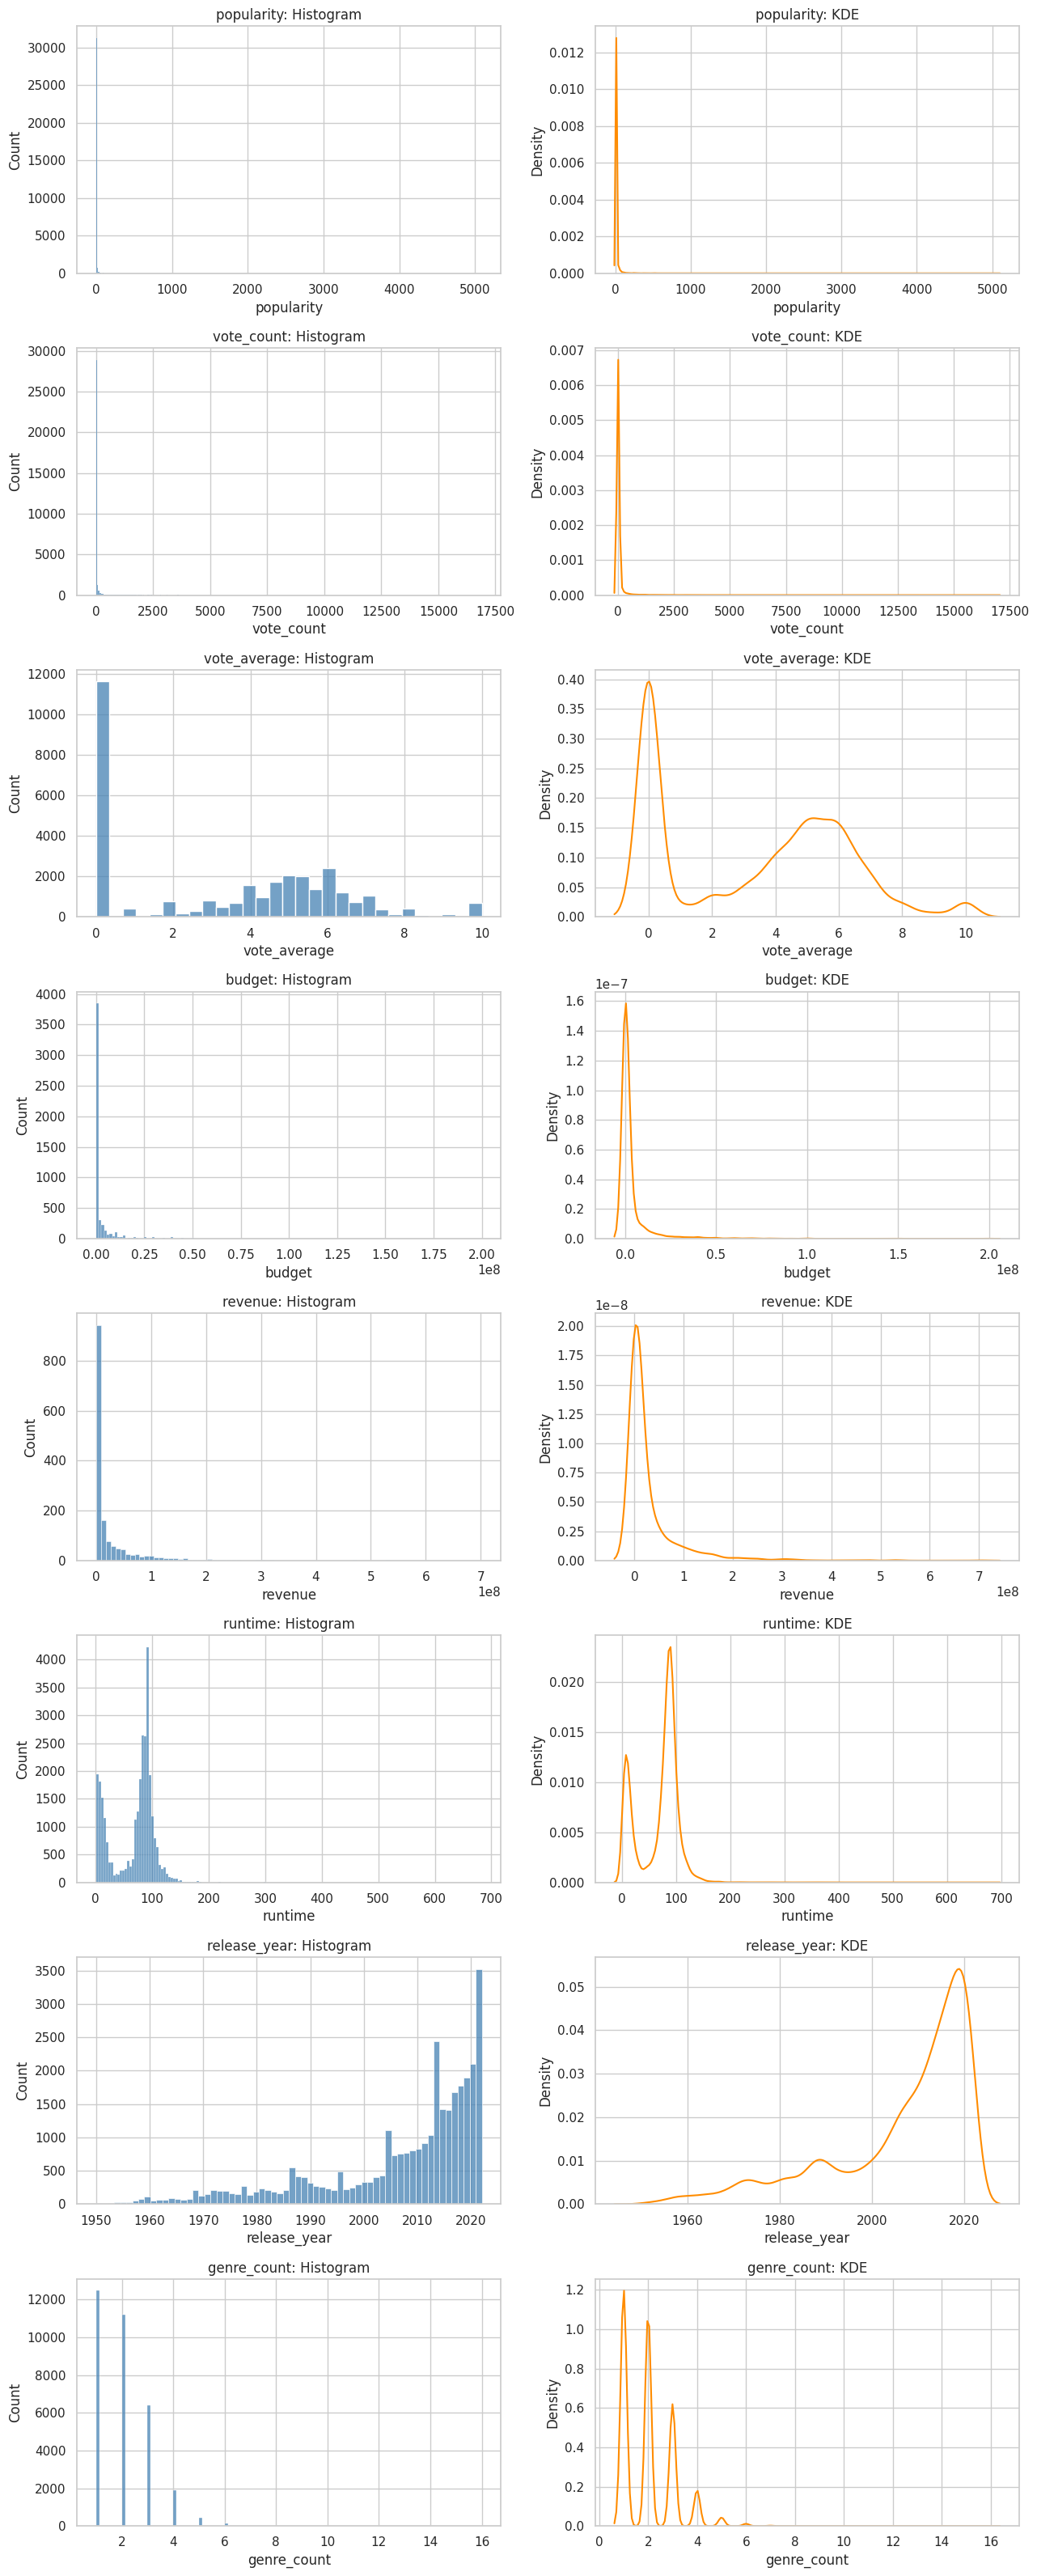

,skewness
popularity,89.790417
vote_count,17.001679
budget,7.281520
revenue,4.338522
genre_count,1.118862
vote_average,0.129749
runtime,-0.002298
release_year,-1.332815


In [11]:
numeric_eda_cols = [
    "popularity", "vote_count", "vote_average",
    "budget", "revenue", "runtime", "release_year", "genre_count"
]
numeric_eda_cols = [c for c in numeric_eda_cols if c in df_clean.columns]

fig, axes = plt.subplots(len(numeric_eda_cols), 2, figsize=(13, 4 * len(numeric_eda_cols)))
for i, col in enumerate(numeric_eda_cols):
    sns.histplot(df_clean[col].dropna(), kde=False, color="steelblue", ax=axes[i, 0])
    axes[i, 0].set_title(f"{col}: Histogram")
    sns.kdeplot(df_clean[col].dropna(), fill=False, color="darkorange", ax=axes[i, 1])
    axes[i, 1].set_title(f"{col}: KDE")
plt.tight_layout()
plt.show()

display(df_clean[numeric_eda_cols].skew(numeric_only=True).sort_values(ascending=False).to_frame("skewness"))

### Distribution observations

Compare the skewness table and plots. Popularity, vote count, budget and revenue may contain extreme right tails. `vote_average` is the regression target and should be inspected, but it is not outlier-capped or scaled with the predictors. For financial fields, remember that zero placeholders were treated as missing in Step 5; this changes the distribution and is intentional for modelling unknown amounts.

## 8. Categorical Analysis — Value Counts and Count Plots
**Owner: Devika**

Inspect common categories. For high-cardinality fields, display only the most frequent categories to keep the plots readable.


Value counts: original_language


,count
original_language,
en,21923
es,1661
ja,1639
pt,676
de,631
id,604
fr,591
it,575
zh,496



Value counts: status


,count
status,
released,32405
in production,69
post production,61
planned,5



Value counts: primary_genre


,count
primary_genre,
horror,19339
comedy,4310
drama,3388
action,1966
fantasy,946
crime,919
animation,841
adventure,399
documentary,360



Value counts: adult


,count
adult,
False,32540


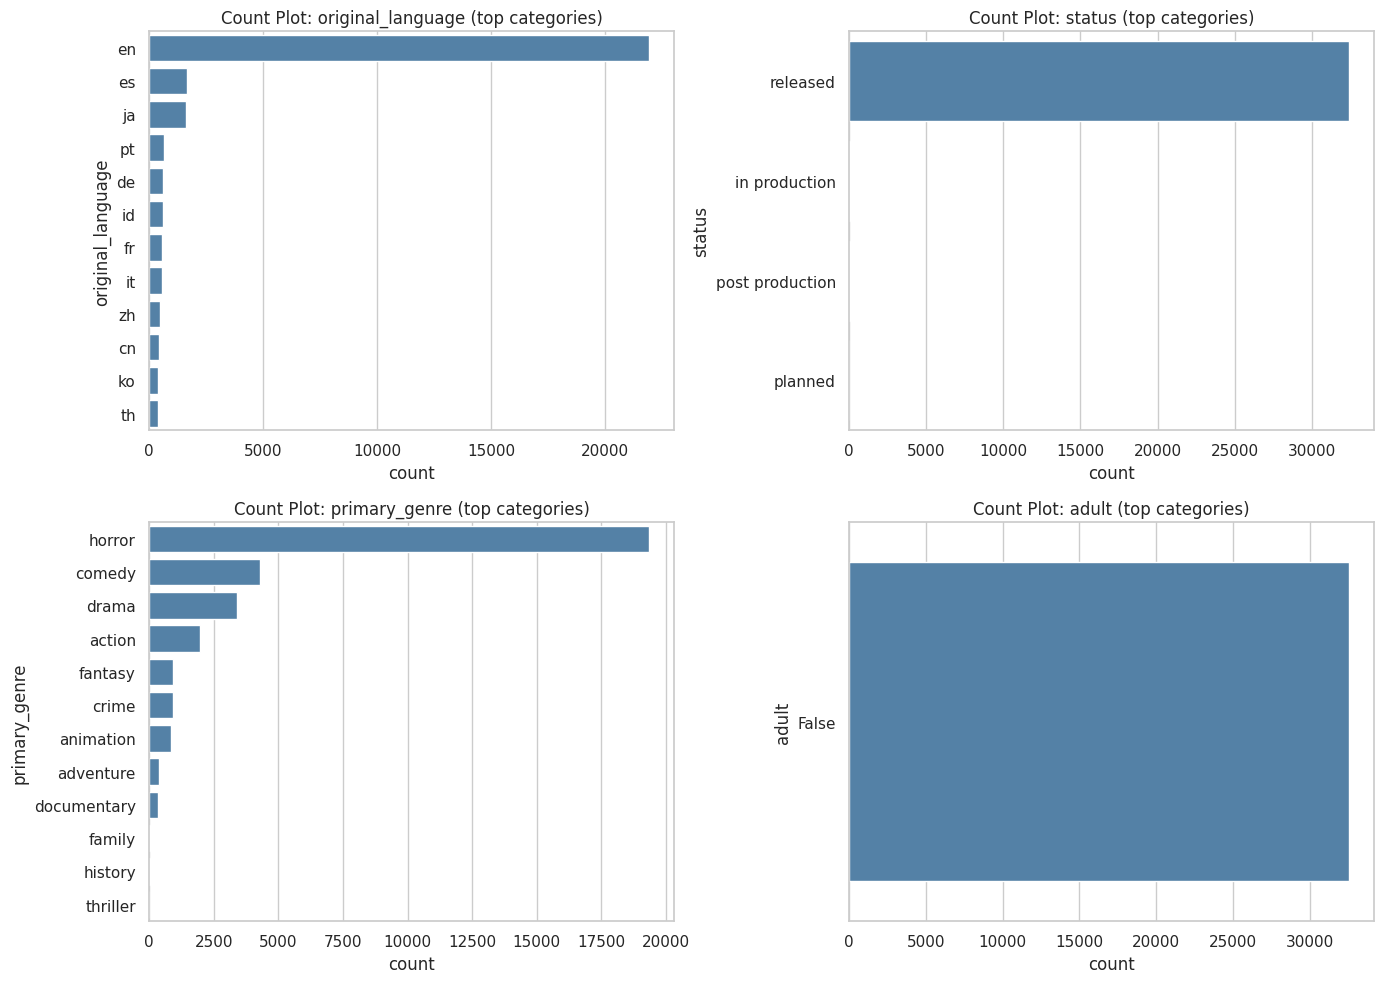

In [12]:
categorical_eda_cols = ["original_language", "status", "primary_genre", "adult"]
for col in categorical_eda_cols:
    print(f"\nValue counts: {col}")
    display(df_clean[col].value_counts(dropna=False).head(20).to_frame("count"))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flat, categorical_eda_cols):
    order = df_clean[col].astype("string").value_counts().head(12).index
    sns.countplot(data=df_clean, y=col, order=order, color="steelblue", ax=ax)
    ax.set_title(f"Count Plot: {col} (top categories)")
plt.tight_layout()
plt.show()

## 9. Feature & Target Separation
**Owner: Devika**

### Target suitability check

The selected target is **`vote_average`**, which represents the movie's average audience rating. Since it is numeric and continuous-like, the prediction task is **regression**, not classification.

- Rows with missing `vote_average` are excluded from supervised modelling.
- `y` contains the target values.
- `X_raw` contains predictor features only; `vote_average` must not appear in it.
- `adult` is not used as a target. It is a constant field in this dataset and is excluded from the predictors.
- Do not use classification-only label encoding, class balancing, or SMOTE for this regression target.


In [13]:
TARGET_COLUMN = "vote_average"

# Ensure the selected target is numeric.
df_clean[TARGET_COLUMN] = pd.to_numeric(df_clean[TARGET_COLUMN], errors="coerce")

print("Target:", TARGET_COLUMN)
print("Target data type:", df_clean[TARGET_COLUMN].dtype)
print("Missing target values:", int(df_clean[TARGET_COLUMN].isna().sum()))
print("Target summary:")
display(df_clean[TARGET_COLUMN].describe())

# A supervised model needs a known target value for every retained row.
df_model = df_clean.dropna(subset=[TARGET_COLUMN]).copy()
y = df_model[TARGET_COLUMN].copy()

# Exclude the target and non-predictive / unsuitable columns from X.
drop_from_features = [
    TARGET_COLUMN, "id", "original_title", "title", "overview", "tagline",
    "release_date", "poster_path", "backdrop_path",
    "genre_names", "collection_name", "adult"
]
X_raw = df_model.drop(columns=[c for c in drop_from_features if c in df_model.columns])

print("Rows retained for modelling:", len(df_model))
print("Feature matrix shape:", X_raw.shape)
print("Target shape:", y.shape)
print("Target accidentally present in X:", TARGET_COLUMN in X_raw.columns)
display(X_raw.head())


Target: vote_average
Target data type: float64
Missing target values: 0
Target summary:


,vote_average
count,32540.000000
mean,3.335728
std,2.876002
min,0.000000
25%,0.000000
50%,4.000000
75%,5.700000
max,10.000000


Rows retained for modelling: 32540
Feature matrix shape: (32540, 12)
Target shape: (32540,)
Target accidentally present in X: False


,original_language,popularity,vote_count,budget,revenue,runtime,status,collection,release_year,release_month,genre_count,primary_genre
0,en,5088.584,902,NaN,9572765.0,99.0,released,760193.0,2022,7,2,horror
1,en,2172.338,584,NaN,56000000.0,93.0,released,NaN,2022,8,3,adventure
2,en,1863.628,114,17000000.0,45000000.0,115.0,released,NaN,2022,9,3,horror
3,en,1071.398,2736,18800000.0,161000000.0,103.0,released,NaN,2022,6,2,horror
4,es,1020.995,83,NaN,NaN,NaN,released,NaN,2022,9,1,horror


## 10. Check Data Leakage
**Owner: Devika**

Identify columns that are identifiers, descriptive text, asset paths, duplicate representations, or fields unsuitable as predictors. The target `vote_average` is explicitly excluded from `X_raw`; keeping it among the predictors would cause direct target leakage. The `adult` field is also excluded because it is constant in this dataset.

Review whether any remaining predictor would be unavailable at the time a rating prediction is made. In particular, `vote_count` is related to the rating data; decide whether it is acceptable for the team's intended prediction scenario and explain that choice in the final report.


In [14]:
leakage_or_unhelpful_columns = [
    "vote_average",         # target: must never be included in X
    "id",                   # database identifier
    "original_title",       # high-cardinality title text
    "title",                # duplicate title representation
    "overview",             # free text not vectorized in this workflow
    "tagline",              # free text not vectorized in this workflow
    "poster_path",          # image asset path, not image features
    "backdrop_path",        # image asset path, not image features
    "collection_name",      # collection label; collection ID/name not modelled here
    "collection",           # collection identifier, not a numeric magnitude
    "adult"                 # constant field; not used as a predictor
]

# Rebuild X from the target-filtered modelling data to make the exclusion explicit.
X_raw = df_model.drop(columns=[c for c in leakage_or_unhelpful_columns if c in df_model.columns])
print("Columns removed:")
print([c for c in leakage_or_unhelpful_columns if c in df_model.columns])
print("\nRemaining feature columns:")
print(X_raw.columns.tolist())
print("\nTarget column excluded from features:", TARGET_COLUMN not in X_raw.columns)


Columns removed:
['vote_average', 'id', 'original_title', 'title', 'overview', 'tagline', 'poster_path', 'backdrop_path', 'collection_name', 'collection', 'adult']

Remaining feature columns:
['original_language', 'release_date', 'popularity', 'vote_count', 'budget', 'revenue', 'runtime', 'status', 'genre_names', 'release_year', 'release_month', 'genre_count', 'primary_genre']

Target column excluded from features: True


## 11. Train-Test Splitting
**Owner: Vyas**

Split the predictor rows and continuous target together so that each feature row stays paired with its correct `vote_average`. All learned feature-preprocessing decisions (imputation, outlier bounds, scaling and encoding) are fitted on `X_train` and then applied to `X_test`. The target remains on its original scale.


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=42
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)
print("\nTraining target summary:")
print(y_train.describe().to_frame("vote_average"))
print("\nTesting target summary:")
print(y_test.describe().to_frame("vote_average"))


Training feature shape: (26032, 13)
Testing feature shape: (6508, 13)
Training target shape: (26032,)
Testing target shape: (6508,)

Training target summary:
       vote_average
count  26032.000000
mean       3.341280
std        2.883678
min        0.000000
25%        0.000000
50%        4.000000
75%        5.700000
max       10.000000

Testing target summary:
       vote_average
count   6508.000000
mean       3.313522
std        2.845199
min        0.000000
25%        0.000000
50%        4.000000
75%        5.600000
max       10.000000


## 12. Numerical Data Preprocessing
**Owner: Vyas**

### 12.1 Separate Numerical Columns
Separate numeric and categorical columns based on the training partition. Datetime columns have already been converted into numeric year/month features.

In [16]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "string", "category", "bool", "boolean"]).columns.tolist()

print("Numerical columns:", numeric_features)
print("Categorical columns:", categorical_features)

Numerical columns: ['popularity', 'vote_count', 'budget', 'revenue', 'runtime', 'release_year', 'release_month', 'genre_count']
Categorical columns: ['original_language', 'status', 'genre_names', 'primary_genre']


### 12.2 Numerical Missing Value Handling

Use median imputation because several numeric variables are skewed and contain extreme values. Fit the imputer on training data only.

In [17]:
numeric_imputer = SimpleImputer(strategy="median")
X_train_num = pd.DataFrame(
    numeric_imputer.fit_transform(X_train[numeric_features]),
    columns=numeric_features,
    index=X_train.index
)
X_test_num = pd.DataFrame(
    numeric_imputer.transform(X_test[numeric_features]),
    columns=numeric_features,
    index=X_test.index
)
print("Missing numerical values after imputation (train):", X_train_num.isna().sum().sum())
print("Missing numerical values after imputation (test):", X_test_num.isna().sum().sum())

Missing numerical values after imputation (train): 0
Missing numerical values after imputation (test): 0


### 12.3 Outlier Detection & Treatment

Use the IQR rule to identify potential outliers in training numerical features. Here, we cap values at the training-set boundary values (winsorization) and apply the same learned bounds to the test set.

In [18]:
outlier_summary = []
outlier_bounds = {}

for col in numeric_features:
    q1 = X_train_num[col].quantile(0.25)
    q3 = X_train_num[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_count = ((X_train_num[col] < lower) | (X_train_num[col] > upper)).sum()
    outlier_bounds[col] = (lower, upper)
    outlier_summary.append([col, lower, upper, int(outlier_count)])

    X_train_num[col] = X_train_num[col].clip(lower=lower, upper=upper)
    X_test_num[col] = X_test_num[col].clip(lower=lower, upper=upper)

display(pd.DataFrame(outlier_summary, columns=["feature", "lower_bound", "upper_bound", "train_outlier_count"]))

,feature,lower_bound,upper_bound,train_outlier_count
0,popularity,-1.882875e+00,4.738125e+00,3471
1,vote_count,-1.650000e+01,2.750000e+01,3976
2,budget,5.000000e+04,5.000000e+04,4125
3,revenue,3.600000e+06,3.600000e+06,1264
4,runtime,-4.150000e+01,1.705000e+02,62
5,release_year,1.973000e+03,2.045000e+03,1305
6,release_month,-7.500000e+00,2.050000e+01,0
7,genre_count,-2.000000e+00,6.000000e+00,25


### 12.4 Feature Scaling

`StandardScaler` is the primary scaling method. Fit scaler on training data only.

In [19]:
standard_scaler = StandardScaler()
X_train_num_scaled = pd.DataFrame(
    standard_scaler.fit_transform(X_train_num),
    columns=numeric_features,
    index=X_train_num.index
)
X_test_num_scaled = pd.DataFrame(
    standard_scaler.transform(X_test_num),
    columns=numeric_features,
    index=X_test_num.index
)